# SimpleRNN, LSTM and GRU for Sequence Classification
This notebook continues with Malo et al. (2014), now using RNNs.

Main topics: building RNNs, data loading, and variable-length sequences.

## 1. Loading the Data
In the previous TextCNN notebook we saved the preprocessed data, so here we just load it.

Since RNNs handle variable-length sequences, we also load the sequence lengths (sqlen).

In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# use the data saved by the TextCNN notebook
train_load = torch.load("data/Malo/Malo_Train.pth", weights_only=True)
# rebuild the dataset with TensorDataset
train_data = TensorDataset(train_load["data"],train_load["lengths"], train_load["labels"])

valid_load = torch.load("data/Malo/Malo_Valid.pth", weights_only=True)
# rebuild the dataset with TensorDataset
valid_data = TensorDataset(valid_load["data"],valid_load["lengths"], valid_load["labels"])

test_load = torch.load("data/Malo/Malo_Test.pth", weights_only=True)
# rebuild the dataset with TensorDataset
test_data = TensorDataset(test_load["data"],test_load["lengths"], test_load["labels"])

In [ ]:
batch_size = 50

train_loader = DataLoader(train_data, shuffle=True, batch_size=batch_size)
valid_loader = DataLoader(valid_data, shuffle=True, batch_size=batch_size)
test_loader = DataLoader(test_data, shuffle=True, batch_size=batch_size)

## 2. Defining the Models

### 2.1 LSTM

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence


# LSTM model
class TextLSTM(nn.Module):
    def __init__(self, embed_model, vocab_size, embedding_dim, hidden_dim, output_size, embed_freeze=True):
        """
        Initialize the components of the TextLSTM model.
        
        Args:
        - vocab_size: vocabulary size (total number of tokens the model accepts).
        - embedding_dim: embedding dimension; each token becomes an embedding_dim-vector.
        - hidden_dim: dimension of the LSTM hidden state.
        - output_size: number of output classes (e.g. 3 for 3-way classification).
        """
        super(TextLSTM, self).__init__()

        # 1. embedding layer
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        # load the pretrained weights
        self.embedding.weight = nn.Parameter(torch.from_numpy(embed_model.vectors)) # all vectors
        # freeze the embedding layer; set to False to train it jointly
        if embed_freeze:
            self.embedding.requires_grad = False
        
        # LSTM layer: a recurrent network for sequence data
        self.lstm = nn.LSTM(
            input_size=embedding_dim,   # input size
            hidden_size=hidden_dim,     # hidden size
            batch_first=True            # the first dim of inputs/outputs is batch_size
        )

        # fully connected layer: map the final LSTM hidden state to class scores
        self.fc = nn.Linear(hidden_dim, output_size)

    def forward(self, x, lengths):
        """
        Define the forward pass.
        
        Args:
        - x: input tensor of shape (batch_size, seq_length)
        - lengths: the actual length of each sequence, shape (batch_size,)
        
        Returns:
        - out: class scores of shape (batch_size, output_size)
        """
        # 1. embedding layer: turn token indices into embedding vectors
        # input: x, shape (batch_size, seq_length)
        # output: x, shape (batch_size, seq_length, embedding_dim)
        x = self.embedding(x)

        # 2. use a PackedSequence
        # convert the padded sequence into a PackedSequence
        packed_x = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)

        # 3. LSTM layer: process the sequence
        # input: packed_x
        # outputs:
        # - packed_out: a PackedSequence object
        # - (hidden, cell): the LSTM's final hidden state
        packed_out, (hidden, cell) = self.lstm(packed_x)

        # 4. unpack the sequence (if you need the full sequence output)
        # lstm_out, _ = pad_packed_sequence(packed_out, batch_first=True)

        # 5. take the last layer's hidden state
        # hidden[-1] is the last layer's hidden state (batch_size, hidden_dim)
        final_hidden = hidden[-1]

        # 6. fully connected layer: map the hidden state to class scores
        # input: final_hidden, shape (batch_size, hidden_dim)
        # output: out, shape (batch_size, output_size)
        out = self.fc(final_hidden)

        return F.log_softmax(out, dim=1)

### 2.2 Simple RNN

In [ ]:
# simple RNN model
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

class TextRNN(nn.Module):
    def __init__(self, embed_model, vocab_size, embedding_dim, hidden_dim, output_size, embed_freeze=True):
        """
        Initialize the components of the TextRNN model.
        
        Args:
        - vocab_size: vocabulary size (total number of tokens the model accepts).
        - embedding_dim: embedding dimension; each token becomes an embedding_dim-vector.
        - hidden_dim: dimension of the RNN hidden state.
        - output_size: number of output classes (e.g. 3 for 3-way classification).
        """
        super(TextRNN, self).__init__()

        # 1. embedding layer
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        # load the pretrained weights
        self.embedding.weight = nn.Parameter(torch.from_numpy(embed_model.vectors)) # all vectors
        # freeze the embedding layer; set to False to train it jointly
        if embed_freeze:
            self.embedding.requires_grad = False
        
        # RNN layer: a simple recurrent network for sequence data
        self.rnn = nn.RNN(
            input_size=embedding_dim,  # input size
            hidden_size=hidden_dim,    # hidden size
            batch_first=True           # the first dim of inputs/outputs is batch_size
        )

        # fully connected layer: map the final RNN hidden state to class scores
        self.fc = nn.Linear(hidden_dim, output_size)

    def forward(self, x, lengths):
        """
        Define the forward pass.
        
        Args:
        - x: input tensor of shape (batch_size, seq_length)
        - lengths: the actual length of each sequence, shape (batch_size,)
        
        Returns:
        - out: class scores of shape (batch_size, output_size)
        """
        # 1. embedding layer: turn token indices into embedding vectors
        # input: x, shape (batch_size, seq_length)
        # output: x, shape (batch_size, seq_length, embedding_dim)
        x = self.embedding(x)

        # 2. use a PackedSequence
        # convert the padded sequence into a PackedSequence
        packed_x = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)

        # 3. RNN layer: process the sequence
        # input: packed_x
        # outputs:
        # - packed_out: a PackedSequence object
        # - hidden: shape (num_layers, batch_size, hidden_dim)
        packed_out, hidden = self.rnn(packed_x)

        # 4. unpack the sequence (if you need the full sequence output)
        # rnn_out, _ = pad_packed_sequence(packed_out, batch_first=True)

        # 5. take the last layer's hidden state:
        # hidden[-1] is the last layer's hidden state (batch_size, hidden_dim)
        final_hidden = hidden[-1]

        # 6. fully connected layer: map the hidden state to class scores
        # input: final_hidden, shape (batch_size, hidden_dim)
        # output: out, shape (batch_size, output_size)
        out = self.fc(final_hidden)

        return F.log_softmax(out, dim=1)

### 2.3 GRU
Note: this GRU supports bidirectionality — notice what changes that requires.

It also adds multiple layers and dropout; you could add similar features to the RNN and LSTM.

In [ ]:
class TextGRU(nn.Module):
    def __init__(self, embed_model, vocab_size, embedding_dim, hidden_dim, output_size, num_layers=1, bidirectional=False, dropout=0.5,embed_freeze=True):
        """
        Initialize the components of the TextGRU model.
        
        Args:
        - vocab_size: vocabulary size.
        - embedding_dim: embedding dimension.
        - hidden_dim: dimension of the GRU hidden state.
        - output_size: number of output classes (e.g. 3 for 3-way classification).
        - num_layers: number of GRU layers.
        - bidirectional: whether to use a bidirectional GRU.
        - dropout: dropout probability.
        """
        super(TextGRU, self).__init__()

        # 1. embedding layer
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        # load the pretrained weights
        self.embedding.weight = nn.Parameter(torch.from_numpy(embed_model.vectors)) # all vectors
        # freeze the embedding layer; set to False to train it jointly
        if embed_freeze:
            self.embedding.requires_grad = False
        
        # GRU layer: process sequence data
        self.gru = nn.GRU(
            input_size=embedding_dim,   # input size
            hidden_size=hidden_dim,     # hidden size
            num_layers=num_layers,      # number of GRU layers
            batch_first=True,           # the first dim of inputs/outputs is batch_size
            bidirectional=bidirectional, # bidirectional or not
            dropout=dropout if num_layers > 1 else 0  # dropout only applies with more than one layer
        )

        # dropout layer: reduce overfitting
        self.dropout = nn.Dropout(dropout)

        # fully connected layer: map the GRU hidden state to class scores
        direction_factor = 2 if bidirectional else 1
        self.fc = nn.Linear(hidden_dim * direction_factor, output_size)

    def forward(self, x, lengths):
        """
        Define the forward pass.
        
        Args:
        - x: input tensor of shape (batch_size, seq_length)
        - lengths: the actual length of each sequence, shape (batch_size,)
        
        Returns:
        - out: class scores of shape (batch_size, output_size)
        """
        # 1. embedding layer: turn token indices into embedding vectors
        x = self.embedding(x)  # (batch_size, seq_length) -> (batch_size, seq_length, embedding_dim)

        # 2. use a PackedSequence
        # convert the padded sequence into a PackedSequence
        packed_x = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)

        # 3. GRU layer: process the sequence
        # input: packed_x
        # outputs:
        # - packed_out: a PackedSequence object
        # - hidden: shape (num_layers * direction_factor, batch_size, hidden_dim)
        packed_out, hidden = self.gru(packed_x)

        # 4. unpack the sequence (if you need the full sequence output)
        # gru_out, _ = pad_packed_sequence(packed_out, batch_first=True)

        # 5. take the last layer's hidden state:
        # handle the last layer of a multi-layer GRU
        if self.gru.bidirectional:
            # concatenate the forward and backward hidden states
            final_hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)  # (batch_size, hidden_dim * 2)
        else:
            # take the last layer's hidden state
            final_hidden = hidden[-1]  # (batch_size, hidden_dim)

        # 6. dropout
        final_hidden = self.dropout(final_hidden)

        # 7. fully connected layer: map the hidden state to class scores
        out = self.fc(final_hidden)  # (batch_size, output_size)

        return F.log_softmax(out, dim=1)

## 3. Training and Test Functions

In [ ]:
# the same train/test functions can be reused (still a classification task)
# define the training function
def train(args, model, device, train_loader, optimizer, epoch):
    """
    Training loop with PackedSequence support.
    """
    model.train()  # switch to training mode
    for batch_idx, (data, lengths, target) in enumerate(train_loader):  # load a batch along with sequence lengths
        data,  target = data.to(device),  target.to(device)  # move data to the device
        optimizer.zero_grad()  # clear the gradient buffers
        output = model(data, lengths)  # pass the data and sequence lengths
        loss = F.nll_loss(output, target)  # compute the loss
        loss.backward()  # backpropagation
        optimizer.step()  # update model parameters


def test(model, device, test_loader):
    """
    Evaluation loop with PackedSequence support.
    """
    model.eval()  # switch to eval mode
    test_loss = 0
    correct = 0
    with torch.no_grad():  # disable autograd
        for data, lengths, target in test_loader:  # load a batch along with sequence lengths
            data,  target = data.to(device),  target.to(device)  # move data to the device
            output = model(data, lengths)  # pass the data and sequence lengths
            test_loss += F.nll_loss(output, target, reduction='sum').item()  # compute and accumulate the loss
            pred = output.argmax(dim=1, keepdim=True)  # get the predictions
            correct += pred.eq(target.view_as(pred)).sum().item()  # accumulate the number of correct predictions

    test_loss /= len(test_loader.dataset)  # average loss
    print("=" * 50)
    print("Evaluation Results:")
    print(f" - Average Loss: {test_loss:.4f}")
    print(f" - Accuracy: {correct}/{len(test_loader.dataset)} "
          f"({100. * correct / len(test_loader.dataset):.2f}%)")
    print("=" * 50)

    return 100. * correct / len(test_loader.dataset)

    


In [ ]:
epochs = 6  # max number of training epochs
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # choose device: GPU (CUDA) if available, else CPU
# device = "mps"
print(device)

cpu


## 4. Loading Pretrained word2vec

In [ ]:
# load the word2vec model via gensim
from gensim.models import KeyedVectors
# use the SLIM model; the full version uses too much memory/VRAM
embed_lookup = KeyedVectors.load_word2vec_format('model/GoogleNews-vectors-negative300-SLIM.bin', 
                                                 binary=True)

pretrained_words = []
for word in embed_lookup.key_to_index:
    pretrained_words.append(word)

## 5. Building the Models

In [ ]:

vocab_size = len(pretrained_words)
output_size = 3 
embedding_dim = len(embed_lookup[pretrained_words[0]]) # 300-dim vectors

hidden_dim = 100
output_size = 3

# Simple RNN
model_RNN = TextRNN(embed_lookup, vocab_size, embedding_dim, hidden_dim, output_size).to(device)
print(model_RNN)

# LSTM
model_LSTM = TextLSTM(embed_lookup, vocab_size, embedding_dim, hidden_dim, output_size).to(device)
print(model_LSTM)

# GRU
model_GRU = TextGRU(embed_lookup, vocab_size, embedding_dim, hidden_dim, output_size).to(device)  #, num_layers=1, bidirectional=False, dropout=0.5,embed_freeze=True
print(model_GRU)

# GRU_bi: bidirectional GRU
model_GRU_bi = TextGRU(embed_lookup, vocab_size, embedding_dim, hidden_dim, output_size, bidirectional=True).to(device)  #, num_layers=1, bidirectional=False, dropout=0.5,embed_freeze=True
print(model_GRU_bi)

# GRU_bi_3: bidirectional GRU, 3 layers
model_GRU_bi_3 = TextGRU(embed_lookup, vocab_size, embedding_dim, hidden_dim, output_size, bidirectional=True, num_layers=3).to(device)  #, num_layers=1, bidirectional=False, dropout=0.5,embed_freeze=True
print(model_GRU_bi_3)

TextRNN(
  (embedding): Embedding(299567, 300)
  (rnn): RNN(300, 100, batch_first=True)
  (fc): Linear(in_features=100, out_features=3, bias=True)
)
TextLSTM(
  (embedding): Embedding(299567, 300)
  (lstm): LSTM(300, 100, batch_first=True)
  (fc): Linear(in_features=100, out_features=3, bias=True)
)
TextGRU(
  (embedding): Embedding(299567, 300)
  (gru): GRU(300, 100, batch_first=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=100, out_features=3, bias=True)
)
TextGRU(
  (embedding): Embedding(299567, 300)
  (gru): GRU(300, 100, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=200, out_features=3, bias=True)
)
TextGRU(
  (embedding): Embedding(299567, 300)
  (gru): GRU(300, 100, num_layers=3, batch_first=True, dropout=0.5, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=200, out_features=3, bias=True)
)


## 6. Run

In [ ]:
epochs = 6

In [ ]:
import time
import torch.optim as optim

models_l = [model_RNN,model_LSTM,model_GRU,model_GRU_bi,model_GRU_bi_3]
model_names = ['RNN','LSTM','GRU','GRU_bi','GRU_bi_3']
resl = []
for li in range(len(models_l)):
    model = models_l[li]
    model_name = model_names[li]

    

    optimizer = optim.Adadelta(model.parameters())
    
    for epoch in range(1, epochs + 1):
        tline = {}
        tline['model_name'] = model_name
        tline['epoch']=epoch
        
        start_time = time.time()  # record start time
        train([], model, device, train_loader, optimizer, epoch)  # train
        train_time = time.time()
        tline['valid_precision'] = test(model, device, valid_loader)  # test
        test_time = time.time()
        train_duration = train_time - start_time
        test_duration = test_time - train_time

        tline['train_duration']=train_duration
        tline['test_duration']=test_duration
        
        print(f"Epoch {epoch}/{epochs} - Trained in {train_duration:.2f} seconds  - Test in {test_duration:.2f} seconds.\n")

        resl.append(tline)


Evaluation Results:
 - Average Loss: 0.6550
 - Accuracy: 418/572 (73.08%)
Epoch 1/6 - Trained in 15.09 seconds  - Test in 0.02 seconds.

Evaluation Results:
 - Average Loss: 0.6126
 - Accuracy: 443/572 (77.45%)
Epoch 2/6 - Trained in 15.65 seconds  - Test in 0.02 seconds.

Evaluation Results:
 - Average Loss: 0.5398
 - Accuracy: 445/572 (77.80%)
Epoch 3/6 - Trained in 17.13 seconds  - Test in 0.02 seconds.

Evaluation Results:
 - Average Loss: 0.4476
 - Accuracy: 480/572 (83.92%)
Epoch 4/6 - Trained in 15.33 seconds  - Test in 0.02 seconds.

Evaluation Results:
 - Average Loss: 0.4967
 - Accuracy: 469/572 (81.99%)
Epoch 5/6 - Trained in 15.70 seconds  - Test in 0.02 seconds.

Evaluation Results:
 - Average Loss: 0.3998
 - Accuracy: 494/572 (86.36%)
Epoch 6/6 - Trained in 16.89 seconds  - Test in 0.03 seconds.

Evaluation Results:
 - Average Loss: 0.5661
 - Accuracy: 447/572 (78.15%)
Epoch 1/6 - Trained in 17.43 seconds  - Test in 0.04 seconds.

Evaluation Results:
 - Average Loss: 0.94

In [ ]:
import pandas as pd
res_df = pd.DataFrame(resl)

In [ ]:
res_df.to_csv('model/RNN_record.csv',index=None,encoding='utf-8_sig')

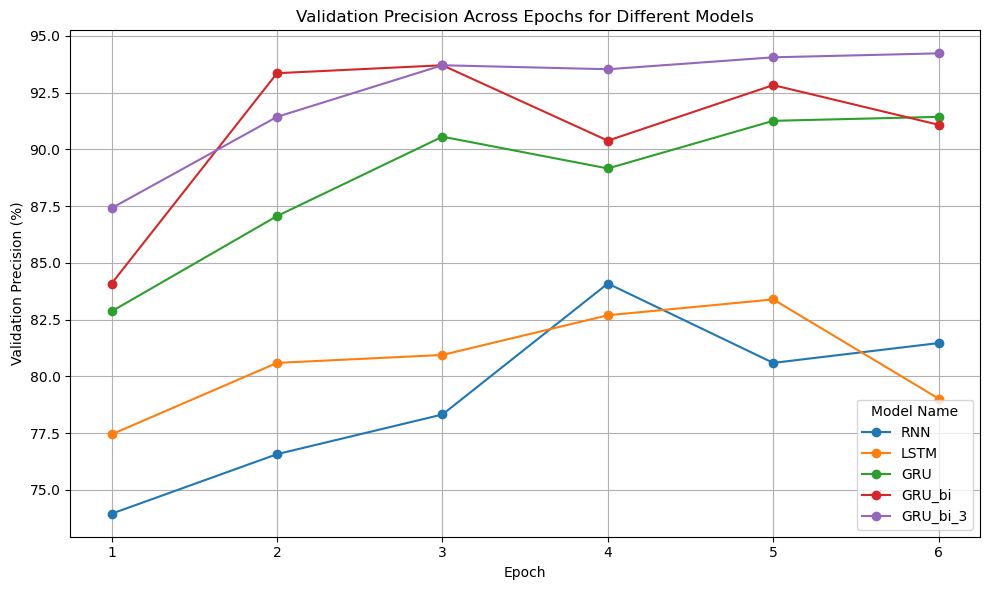

In [ ]:
import matplotlib.pyplot as plt
data = res_df

# get the unique model names
models = data['model_name'].unique()

# line plot of validation accuracy
plt.figure(figsize=(10, 6))
for model in models:
    model_data = data[data['model_name'] == model]
    plt.plot(model_data['epoch'], model_data['valid_precision'], label=model, marker='o')

# add title and axis labels
plt.title('Validation Precision Across Epochs for Different Models')
plt.xlabel('Epoch')
plt.ylabel('Validation Precision (%)')
plt.legend(title='Model Name')
plt.grid(True)
plt.tight_layout()

# show the plot
plt.show()

In [ ]:
avg_durations = res_df.groupby('model_name')[['train_duration', 'test_duration']].mean()

# (optional but recommended) print avg_durations to check its structure and content
print("Average per-model durations computed from res_df (avg_durations):")
print(avg_durations)
print("\nData ready; you can now run the plotting code below.")


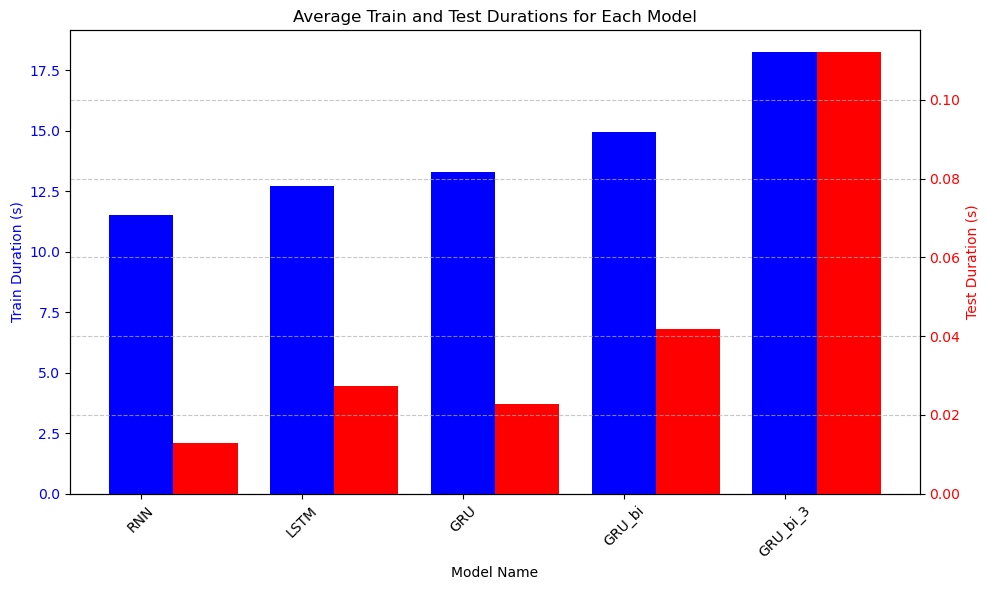

In [ ]:
# desired ordering
desired_order = ['RNN', 'LSTM', 'GRU', 'GRU_bi', 'GRU_bi_3']

# reorder according to the desired ordering
avg_durations_ordered = avg_durations.loc[desired_order]

# bar chart
fig, ax1 = plt.subplots(figsize=(10, 6))

# bar width
bar_width = 0.4
index = range(len(avg_durations_ordered))

# left axis: train_duration
ax1.bar(index, avg_durations_ordered['train_duration'], bar_width, label='Train Duration', color='b')
ax1.set_ylabel('Train Duration (s)', color='b')
ax1.tick_params(axis='y', labelcolor='b')
ax1.set_xlabel('Model Name')
ax1.set_xticks(index)
ax1.set_xticklabels(avg_durations_ordered.index, rotation=45)

# right axis: test_duration
ax2 = ax1.twinx()
ax2.bar([i + bar_width for i in index], avg_durations_ordered['test_duration'], bar_width, label='Test Duration', color='r')
ax2.set_ylabel('Test Duration (s)', color='r')
ax2.tick_params(axis='y', labelcolor='r')

# add grid and title
plt.title('Average Train and Test Durations for Each Model')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# adjust layout
fig.tight_layout()

# show the plot
plt.show()